## Import Library

In [1]:
# ==========================================
# IMPORT SEMUA LIBRARY YANG DIBUTUHKAN
# ==========================================
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import MobileNetV3Small
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
import os
from pathlib import Path
import time
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report
import random
import pandas as pd
from tensorflow import keras
from tensorflow.keras.utils import to_categorical
from sklearn.model_selection import train_test_split
from sklearn.utils import class_weight as cw_utils
from PIL import Image
import warnings
warnings.filterwarnings('ignore')

print('Library berhasil diimport')

print("TensorFlow Version:", tf.__version__)

I0000 00:00:1785927437.310303    2989 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


Library berhasil diimport
TensorFlow Version: 2.21.0


## Pengecekan Perangkat Keras (GPU/CPU)

In [2]:
physical_devices = tf.config.list_physical_devices('GPU')
if len(physical_devices) > 0:
    print(f"Menggunakan GPU: {physical_devices[0].name}")
    try:
        tf.config.experimental.set_memory_growth(physical_devices[0], True)
        print("   -> Memory growth diaktifkan.")
    except Exception as e:
        print("   -> Gagal mengatur memory growth:", e)
else:
    print("Menggunakan CPU. Proses pelatihan mungkin berjalan jauh lebih lambat.")

Menggunakan GPU: /physical_device:GPU:0
   -> Memory growth diaktifkan.


## Load Dataset

In [3]:
# Konfigurasi Path dan Seed
PATH_DATASET = Path('DATASET')
SYNTHETIC_DIR = Path('DATASET_NCD_SINTETIS')
BATCH_SIZE = 32
IMAGE_SIZE = (224, 224)
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

# Memuat dataset murni ke dalam DataFrame
image_extensions = ['.jpg']
data = []

if PATH_DATASET.exists():
    for class_name in os.listdir(PATH_DATASET):
        class_path = PATH_DATASET / class_name
        if class_path.is_dir():
            for img_path in class_path.iterdir():
                if img_path.is_file() and img_path.suffix.lower() in image_extensions:
                    data.append({'filepath': str(img_path), 'label': class_name})

df = pd.DataFrame(data)
num_classes = len(df['label'].unique())

print(f"Total gambar : {len(df)}")
print(f"Jumlah kelas : {num_classes}")

Total gambar : 6812
Jumlah kelas : 4


## Exploratory Data Analysis (Sebelum Penyeimbangan)

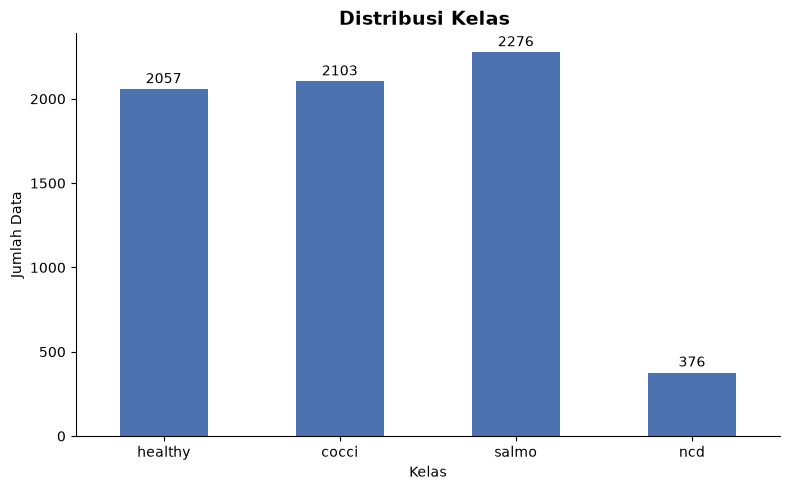

In [4]:
expected_classes = ['healthy', 'cocci', 'salmo', 'ncd']

# Menghitung distribusi kelas sebelum diapa-apakan
class_counts = df['label'].value_counts().reindex(expected_classes).fillna(0).astype(int)

plt.figure(figsize=(8,5))
ax = class_counts.plot(kind='bar', color='#4C72B0')
plt.title('Distribusi Kelas ', fontsize=14, fontweight='bold')
ax.set_xlabel('Kelas')
ax.set_ylabel('Jumlah Data')
ax.tick_params(axis='x', rotation=0)

for container in ax.containers:
    ax.bar_label(container, fmt='%d', padding=2)

sns.despine()
plt.tight_layout()
plt.show()

## Preprocessing & Penyeimbangan Data (DCGAN)

In [5]:
# 1. Split Data (80% Train, 20% Test)
train_df, test_df = train_test_split(
    df, test_size=0.2, random_state=SEED, stratify=df['label']
)

# 2. Penambahan Data Sintetis DCGAN ke dalam Train Set
synthetic_data = []
if SYNTHETIC_DIR.exists():
    for img_path in SYNTHETIC_DIR.iterdir():
        if img_path.is_file() and img_path.suffix.lower() in image_extensions:
            synthetic_data.append({'filepath': str(img_path), 'label': 'ncd'})
    
    if synthetic_data:
        synthetic_df = pd.DataFrame(synthetic_data)
        train_df = pd.concat([train_df, synthetic_df], ignore_index=True)
        train_df = train_df.sample(frac=1, random_state=SEED).reset_index(drop=True)
        print(f"Berhasil menambahkan {len(synthetic_df)} citra sintetis DCGAN ke Data Latih (NCD).")

print(f"Total Data Latih (Train) : {len(train_df)}")
print(f"Total Data Uji (Test)    : {len(test_df)}")

Berhasil menambahkan 1520 citra sintetis DCGAN ke Data Latih (NCD).
Total Data Latih (Train) : 6969
Total Data Uji (Test)    : 1363


## EDA (Sesudah Penyeimbangan)

<Figure size 800x500 with 0 Axes>

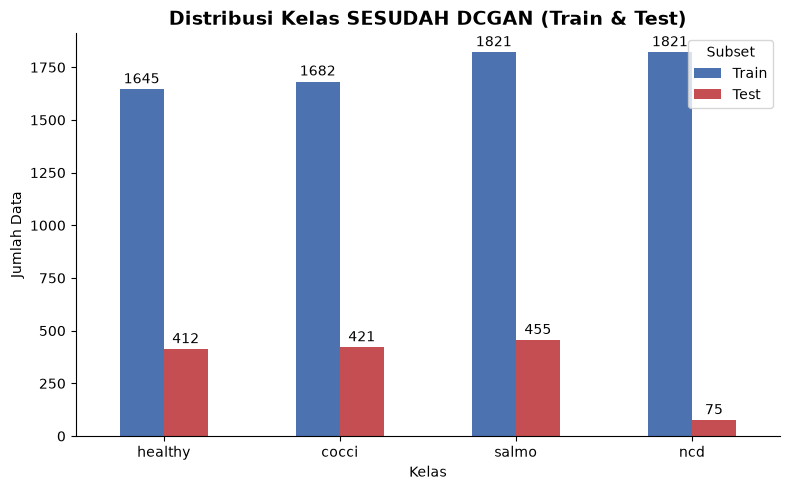

In [6]:
# Hitung Sesudah
split_counts_after = pd.concat([
    train_df['label'].value_counts().rename('Train'),
    test_df['label'].value_counts().rename('Test')
], axis=1).reindex(expected_classes).fillna(0).astype(int)

# Plotting
plt.figure(figsize=(8,5))
ax = split_counts_after.plot(kind='bar', color=['#4C72B0', '#C44E52'], figsize=(8,5))

plt.title('Distribusi Kelas SESUDAH DCGAN (Train & Test)', fontsize=14, fontweight='bold')
ax.set_xlabel('Kelas')
ax.set_ylabel('Jumlah Data')
ax.tick_params(axis='x', rotation=0)

for container in ax.containers:
    ax.bar_label(container, fmt='%d', padding=2)

ax.legend(title='Subset', loc='upper right')

sns.despine()
plt.tight_layout()
plt.show()

## 7. ImageDataGenerator & Normalisasi\n

In [7]:
def normalize_to_minus_one_one(image):
    return (image / 127.5) - 1.0

train_datagen = ImageDataGenerator(preprocessing_function=normalize_to_minus_one_one)
test_datagen = ImageDataGenerator(preprocessing_function=normalize_to_minus_one_one)

train_generator = train_datagen.flow_from_dataframe(
    dataframe=train_df,
    x_col='filepath',
    y_col='label',
    target_size=IMAGE_SIZE, 
    batch_size=BATCH_SIZE, 
    class_mode='categorical',
    shuffle=True, 
    seed=SEED
)

test_generator = test_datagen.flow_from_dataframe(
    dataframe=test_df, 
    x_col='filepath', 
    y_col='label',
    target_size=IMAGE_SIZE, 
    batch_size=BATCH_SIZE, 
    class_mode='categorical',
    shuffle=False
)

Found 6969 validated image filenames belonging to 4 classes.
Found 1363 validated image filenames belonging to 4 classes.


## 8. Pemodelan

In [8]:
# Base Model (Transfer Learning)
base_model = MobileNetV3Small(
    weights='imagenet',
    include_top=False,
    input_shape=(224, 224, 3),
    include_preprocessing=False
)

# Membekukan layer base model
base_model.trainable = False

# Klasifikasi Head
x = base_model.output
x = GlobalAveragePooling2D()(x)
predictions = Dense(num_classes, activation='softmax')(x)

model = Model(inputs=base_model.input, outputs=predictions)
print('Backbone MobileNetV3Small dibekukan; classifier head tetap dilatih.')

I0000 00:00:1785669660.896437    8520 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 1763 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 2050, pci bus id: 0000:01:00.0, compute capability: 8.6


Backbone MobileNetV3Small dibekukan; classifier head tetap dilatih.


In [9]:
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv (Conv2D)       │ (None, 112, 112,  │        432 │ input_layer[0][0] │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv_bn             │ (None, 112, 112,  │         64 │ conv[0][0]        │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 112, 112,  │          0 │ conv_bn[0][0]     │
│ (Activation)        │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 113, 113,  │          0 │ activation[0][0]  │
│ (ZeroPadding2D)     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 56, 56,    │        144 │ expanded_conv_de… │
│ (DepthwiseConv2D)   │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 56, 56,    │         64 │ expanded_conv_de… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu (ReLU)        │ (None, 56, 56,    │          0 │ expanded_conv_de… │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_sque… │ (None, 1, 1, 16)  │          0 │ re_lu[0][0]       │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_sque… │ (None, 1, 1, 8)   │        136 │ expanded_conv_sq… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_sque… │ (None, 1, 1, 8)   │          0 │ expanded_conv_sq… │
│ (ReLU)              │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_sque… │ (None, 1, 1, 16)  │        144 │ expanded_conv_sq… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 1, 1, 16)  │          0 │ expanded_conv_sq… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_1 (ReLU)      │ (None, 1, 1, 16)  │          0 │ add[0][0]         │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multiply (Multiply) │ (None, 1, 1, 16)  │          0 │ re_lu_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_sque… │ (None, 56, 56,    │          0 │ re_lu[0][0],      │
│ (Multiply)          │ 16)               │            │ multiply[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 56, 56,    │        256 │ expanded_conv_sq… │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 56, 56,    │         64 │ expanded_conv_pr

 Total params: 941,428 (3.59 MB)

 Trainable params: 2,308 (9.02 KB)

 Non-trainable params: 939,120 (3.58 MB)

## Pelatihan

In [ ]:

# ==========================================
# PELATIHAN MODEL
# ==========================================

EPOCHS = 10
LEARNING_RATE = 0.0001

# ==========================================
# COMPILE MODEL
# ==========================================

optimizer = Adam(
    learning_rate=LEARNING_RATE
)

model.compile(
    loss='categorical_crossentropy',
    optimizer=optimizer,
    metrics=[
        tf.keras.metrics.F1Score(
            average='weighted',
            name='f1_score'
        )
    ]
)

In [11]:
# Agar urutan generator dimulai kembali dari batch pertama
train_generator.reset()

print("Memulai Pelatihan Model...")
history = model.fit(
    train_generator,
    epochs=EPOCHS,
    verbose=1
)

# ==========================================
# DIREKTORI PENYIMPANAN MODEL
# ==========================================
MODEL_SAVE_DIR = Path('model_outputs/MobileNetV3_DCGAN')
MODEL_SAVE_DIR.mkdir(parents=True, exist_ok=True)
MODEL_SAVE_PATH = MODEL_SAVE_DIR / 'model_dcgan_final.keras'

# ==========================================
# MENYIMPAN MODEL AKHIR
# ==========================================
model.save(MODEL_SAVE_PATH)

print("Training selesai!")
print("Model berhasil disimpan di:")
print(MODEL_SAVE_PATH)

Memulai Pelatihan Model...
Epoch 1/10


I0000 00:00:1785669669.695890    8520 generator_dataset_op.cc:213] Memory patch applied: M_TRIM_THRESHOLD=128 kb was set.
I0000 00:00:1785669677.086997    9052 service.cc:153] XLA service 0x7abf08033610 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1785669677.087053    9052 service.cc:161]   StreamExecutor [0]: NVIDIA GeForce RTX 2050, Compute Capability 8.6 (Driver: 13.3.0; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.24.0)
I0000 00:00:1785669677.361314    9052 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1785669679.080203    9052 cuda_dnn.cc:461] Loaded cuDNN version 92400
I0000 00:00:1785669679.234431    9052 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_8050__.150


  1/218 ━━━━━━━━━━━━━━━━━━━━ 3:54:20 65s/step - f1_score: 0.1936 - loss: 2.1028

I0000 00:00:1785669734.345796    9052 device_compiler.h:208] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


 13/218 ━━━━━━━━━━━━━━━━━━━━ 6:46 2s/step - f1_score: 0.2790 - loss: 1.8230

I0000 00:00:1785669761.824100    9050 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_8050__.150


218/218 ━━━━━━━━━━━━━━━━━━━━ 542s 2s/step - f1_score: 0.5464 - loss: 1.1241
Epoch 2/10
218/218 ━━━━━━━━━━━━━━━━━━━━ 340s 2s/step - f1_score: 0.8356 - loss: 0.5681
Epoch 3/10
218/218 ━━━━━━━━━━━━━━━━━━━━ 292s 1s/step - f1_score: 0.8972 - loss: 0.3973
Epoch 4/10
218/218 ━━━━━━━━━━━━━━━━━━━━ 297s 1s/step - f1_score: 0.9183 - loss: 0.3176
Epoch 5/10
218/218 ━━━━━━━━━━━━━━━━━━━━ 295s 1s/step - f1_score: 0.9299 - loss: 0.2701
Epoch 6/10
218/218 ━━━━━━━━━━━━━━━━━━━━ 288s 1s/step - f1_score: 0.9354 - loss: 0.2377
Epoch 7/10
218/218 ━━━━━━━━━━━━━━━━━━━━ 285s 1s/step - f1_score: 0.9389 - loss: 0.2143
Epoch 8/10
218/218 ━━━━━━━━━━━━━━━━━━━━ 298s 1s/step - f1_score: 0.9441 - loss: 0.1958
Epoch 9/10
218/218 ━━━━━━━━━━━━━━━━━━━━ 286s 1s/step - f1_score: 0.9493 - loss: 0.1808
Epoch 10/10
218/218 ━━━━━━━━━━━━━━━━━━━━ 293s 1s/step - f1_score: 0.9506 - loss: 0.1687
Training selesai!
Model berhasil disimpan di:
model_outputs/MobileNetV3_DCGAN/model_dcgan_final.keras


## Evaluasi Akhir

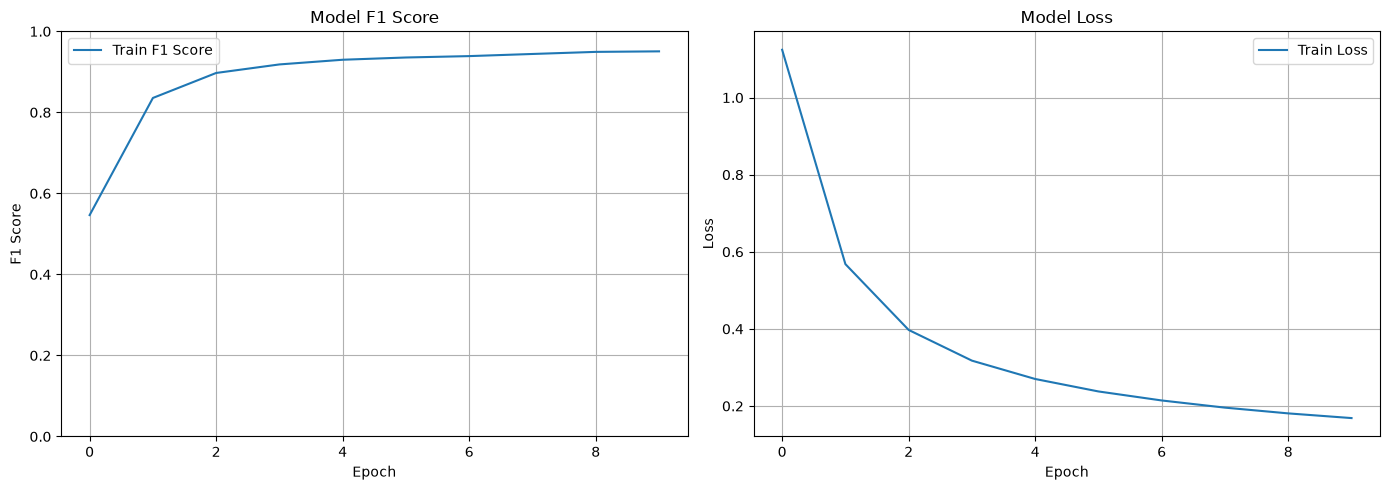

In [ ]:
# 1. Grafik Learning Curve
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Accuracy / F1 Score
ax1.plot(history.history['f1_score'], label='Train F1 Score')
ax1.set_title('Model F1 Score')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('F1 Score')
ax1.set_ylim(0, 1)
ax1.legend()
ax1.grid(True)

# Loss
ax2.plot(history.history['loss'], label='Train Loss')
ax2.set_title('Model Loss')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Loss')
ax2.legend()
ax2.grid(True)

plt.tight_layout()
plt.show()



In [13]:
print("Mengevaluasi model pada data test...\n")

test_generator.reset()
test_loss, f1_score = model.evaluate(test_generator, verbose=1)

print(f"\nTest Loss    : {test_loss:.4f}")
print(f"Test F1 Score: {f1_score:.4f} ({f1_score:.2%})")

Mengevaluasi model pada data test...

43/43 ━━━━━━━━━━━━━━━━━━━━ 111s 2s/step - f1_score: 0.9417 - loss: 0.2053

Test Loss    : 0.2053
Test F1 Score: 0.9417 (94.17%)


43/43 ━━━━━━━━━━━━━━━━━━━━ 70s 2s/step


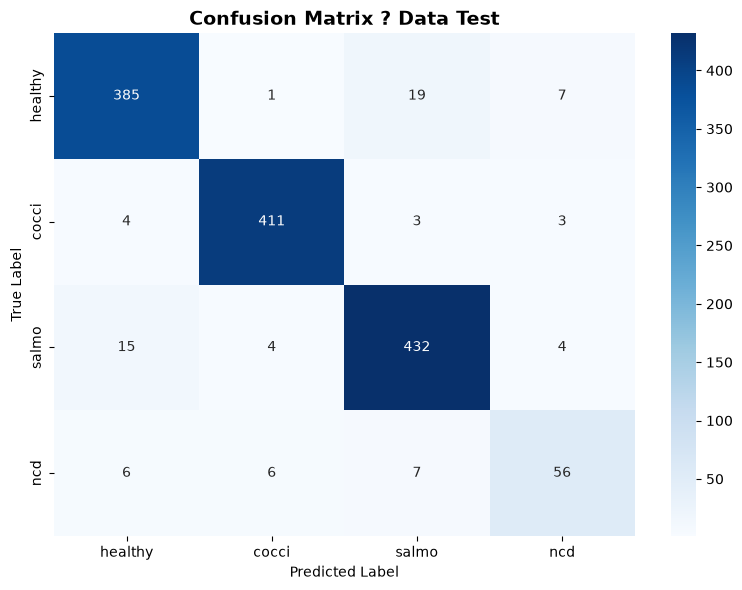

In [14]:
# ==========================================
# CONFUSION MATRIX
# ==========================================
test_generator.reset()
y_pred_probs = model.predict(test_generator, verbose=1)
y_pred = np.argmax(y_pred_probs, axis=1)
y_true = test_generator.classes
class_labels = list(test_generator.class_indices.keys())
display_class_labels = expected_classes
display_label_indices = [test_generator.class_indices[label] for label in display_class_labels]

cm = confusion_matrix(y_true, y_pred, labels=display_label_indices)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm, annot=True, fmt='d', cmap='Blues',
    xticklabels=display_class_labels,
    yticklabels=display_class_labels
)
plt.title('Confusion Matrix ? Data Test', fontsize=14, fontweight='bold')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.tight_layout()
plt.show()

In [15]:
# ==========================================
# CLASSIFICATION REPORT
# ==========================================
print("Classification Report:\n")
print(classification_report(
    y_true,
    y_pred,
    labels=display_label_indices,
    target_names=display_class_labels,
    digits=4
))

Classification Report:

              precision    recall  f1-score   support

     healthy     0.9390    0.9345    0.9367       412
       cocci     0.9739    0.9762    0.9751       421
       salmo     0.9371    0.9495    0.9432       455
         ncd     0.8000    0.7467    0.7724        75

    accuracy                         0.9420      1363
   macro avg     0.9125    0.9017    0.9069      1363
weighted avg     0.9415    0.9420    0.9417      1363



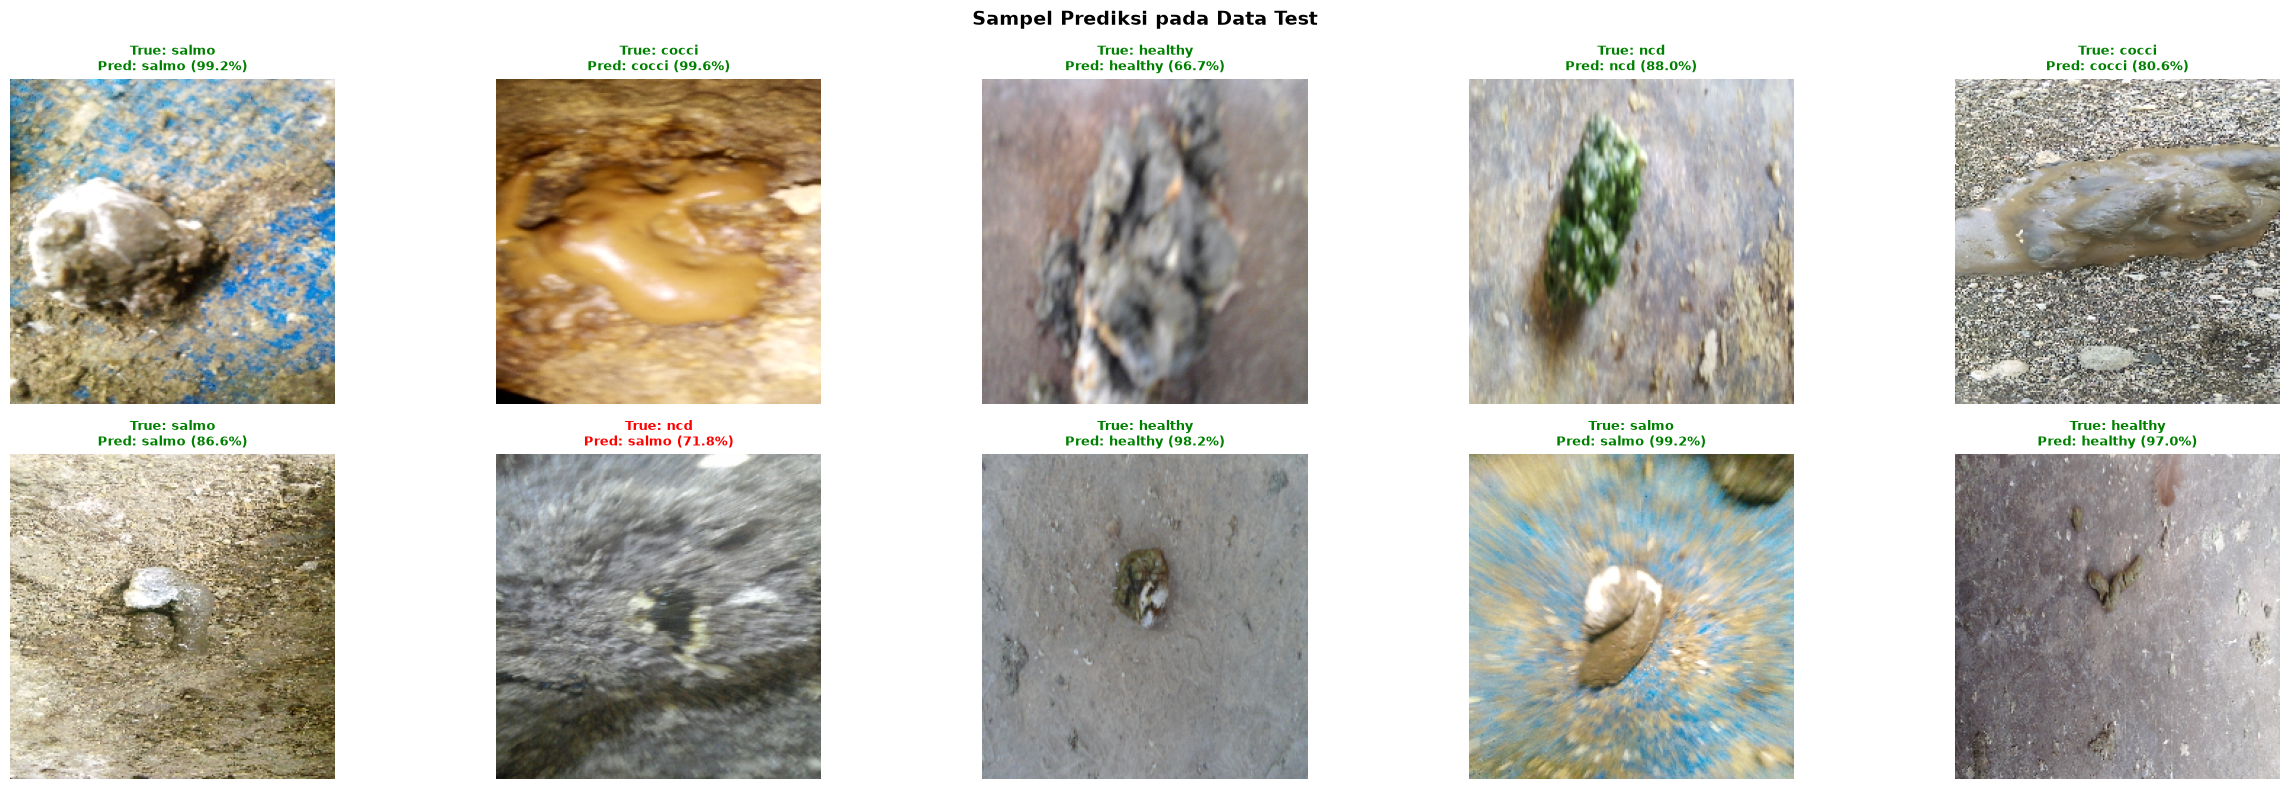

In [16]:
# ==========================================
# VISUALISASI PREDIKSI SAMPEL
# ==========================================
test_generator.reset()
sample_batch_x, sample_batch_y = next(test_generator)
sample_preds = model.predict(sample_batch_x, verbose=0)

fig, axes = plt.subplots(2, 5, figsize=(25, 8))
for i, ax in enumerate(axes.flat):
    if i >= len(sample_batch_x):
        break

    img_show = sample_batch_x[i]

    if img_show.min() < 0:
        img_show = (img_show + 1) / 2
    elif img_show.max() > 1:
        img_show = img_show / 255.0

    ax.imshow(img_show)
    true_label = class_labels[np.argmax(sample_batch_y[i])]
    pred_label = class_labels[np.argmax(sample_preds[i])]
    confidence = np.max(sample_preds[i]) * 100
    color = 'green' if true_label == pred_label else 'red'
    ax.set_title(f'True: {true_label}\nPred: {pred_label} ({confidence:.1f}%)',
                 fontsize=9, color=color, fontweight='bold')
    ax.axis('off')

plt.suptitle('Sampel Prediksi pada Data Test', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()